Rubtcova Vera  
Algorithms Task 5

## Goal  
The use of different representations of graphs and basic algorithms on graphs
(Depth-first search and Breadth-first search)  

In [ ]:
import math
import pandas as pd
import random
import matplotlib.pyplot as plt

## Task  
-  Generate a random adjacency matrix for a simple undirected unweighted graph
with 100 vertices and 200 edges (note that the matrix should be symmetric and
contain only 0s and 1s as elements). Transfer the matrix into an adjacency list.
Visualize the graph and print several rows of the adjacency matrix and the
adjacency list. Which purposes is each representation more convenient for?
-  Use Depth-first search to find connected components of the graph and Breadth
first search to find a shortest path between two random vertices. Analyse the results
obtained.
-  Describe the data structures and design techniques used within the algorithms.

In [ ]:
def generate_matrix():
  matrix = [[0] * 100 for _ in range(100)]
  edges = 0
  while edges < 200:
    i, j = random.sample(range(100), 2)
    if matrix[i][j] == 0:
      matrix[i][j] = matrix[j][i] = 1
      edges += 1
  return matrix

In [ ]:
def generate_list(matrix):
  adjacency_list = {}
  for i in range(len(matrix)):
    neighbours = []
    for j in range(len(matrix)):
      if matrix[i][j] == 1:
        neighbours.append(j)
    adjacency_list[i] = neighbours
  return adjacency_list

In [ ]:
def get_plot(adj_list):
  plt.figure(figsize=(8,5))
  xs, ys = [], []
  for i in range(len(adj_list)):
    angle = 2 * math.pi * i / 100
    xs.append(math.cos(angle))
    ys.append(math.sin(angle))
  for i in range(len(adj_list)):
    for j in adj_list[i]:
        if j > i:
          plt.plot([xs[i], xs[j]], [ys[i], ys[j]], color="lightblue", linewidth = 0.5)
  plt.scatter(xs, ys, s=20)
  plt.show()


In [ ]:
random.seed(200)
matrix = generate_matrix()
adj_list = generate_list(matrix)

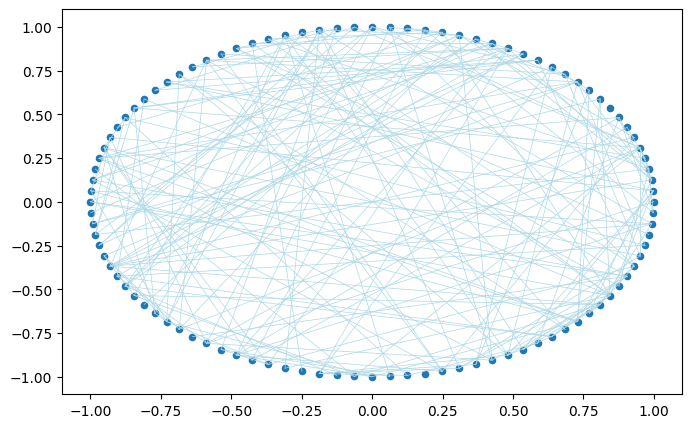

In [ ]:
get_plot(adj_list)

In [ ]:
for i in range(5):
  print(matrix[i])

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 

In [ ]:
for i in range(5):
  print(adj_list[i])

[65]
[38, 44, 83, 84, 88, 91]
[5, 8, 12, 17, 19, 56, 89]
[5, 18, 31, 53, 92, 99]
[7, 38]


An adjacency matrix makes it easy to determine whether an edge exists between two vertices. However, it consumes a large amount of memory while remaining mostly empty.
An adjacency list is more suitable when a vertex has few edges (as in this case). It allows for quick traversal of a vertex's neighbors and requires less memory.

In [ ]:
def dfs(v, adj_list, visited, component):
  visited[v] = True
  component.append(v)
  for i in adj_list[v]:
    if not visited[i]:
      dfs(i,  adj_list, visited, component)

In [ ]:
def find_components(adj_list):
  visited = [False] * len(adj_list)
  components = []
  for i in range(len(adj_list)):
    if not visited[i]:
      component = []
      dfs(i, adj_list, visited, component)
      components.append(component)
  return components

In [ ]:
def bfs(start, adj_list):
  visited = [False] * len(adj_list)
  visited[start] = True
  queue = []
  queue.append(start)
  parents = [None] * len(adj_list)
  for v in queue:
    for i in adj_list[v]:
      if not visited[i]:
        queue.append(i)
        parents[i] = v
        visited[i] = True
  return parents


In [ ]:
def get_path(start, finish, adj_list):
  parents = bfs(start, adj_list)
  if (finish == start) or parents[finish] == None:
    return None
  else:
    path = []
    v = finish
    while v != None:
      path.append(v)
      v = parents[v]
    return path[::-1]

In [ ]:
random.seed(3)
components = find_components(adj_list)
start, finish = sorted(random.sample(range(100), 2))
path = get_path(start, finish, adj_list)

In [ ]:
print(f"The number and length of components of graph:\n"
f"{len(components)} : {[(len(c)) for c in components]}\n"
f"The path between {start} and {finish}:\n"
f"{path}")

The number and length of components of graph:
3 : [98, 1, 1]
The path between 30 and 75:
[30, 62, 75]


In [ ]:
lens = []
no_path = 0
for _ in range(100):
  start, finish = sorted(random.sample(range(100), 2))
  path = get_path(start, finish, adj_list)
  if path is None:
    no_path += 1
  else:
    lens.append(len(path) - 1)
print(f"Without path: {no_path}\n"
f"Average path length: {(sum(lens) / len(lens)):.2f}\n"
f"Max length: {max(lens)}")

Without path: 4
Average path length: 3.49
Max length: 6


## Conclusion
The DFS method identified three connected components: one large component containing almost all vertices, and two consisting of a single vertex each—a logical result given the specified number of vertices and edges. The graph is effectively connected.   
The BFS method found a shortest path of two edges between two randomly selected vertices. Since the result depends on the random selection, a run involving 100 pairs of start and end points yielded a maximum path length of 6 edges and an average near 3.

#### Data structures and design techniques

To implement the algorithms for this assignment, the following data structures were used: a matrix (for the adjacency matrix), a dictionary (for the adjacency list), and a queue (to implement BFS); arrays (in the form of lists) were also utilized. Regarding design techniques, recursion—specifically calling a function within itself—was employed to implement the DFS method.